# Experimento A/B en página de inicio

El objetivo de este proyecto es evaluar un **experimento A/B** realizado en una página de inicio (landing page) con versiónes **A y B** para apoyar una **decisión de negocio basada en datos**.

---

El archivo `landing_experiment.csv` contiene información de usuarios expuestos a dos versiones de la página de inicio (landing page) dentro del experimento A/B. Incluye región, dispositivo, fuente de tráfico, tipo de usuario, conversión y gasto.

El análisis sigue una lógica clara y progresiva:

1. 🔍 Explorar y validar los datos.

2. 💰 Comparar el **gasto promedio** por usuario entre la página A y B.

3. 🎯 Comparar la **tasa de conversión** entre la página A y B.

4. 🌐 Revisar **la relación entre la fuente de tráfico y la conversión**.

5. 👤 Revisar **la relación entre el tipo de usuario y la conversión**.

6. 📈 **Visualizar los resultados**: Respalda tus conclusiones mediante gráficos claros.

Se aplican **puebas estadísticas apropiados** para comparar las páginas y **recomendar qué versión es mejor**, justificando la decisión con datos.

## 🧩 Paso 1: Cargar y validar los datos

### 1.1 Carga de datos y vista rápida

In [3]:
# importar librerías
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from statsmodels.stats.proportion import proportions_ztest, proportion_confint

In [4]:
# cargar archivo
df = pd.read_csv('/datasets/landing_experiment.csv')

**Vista previa e información general del conjunto de datos**

In [5]:
# mostrar las primeras 5 filas
df.head()

,user_id,date,landing,region,dispositivo,traffic_source,user_type,converted,gasto
0,26f3052e-8500-44ea-8fff-06de65258abb,2026-01-01,A,Norte,Mobile,Email,Recurrente,1,38.08
1,92378c09-4bbf-40c7-945e-82b84f392d22,2026-01-23,A,Occidente,Mobile,Organic,Nuevo,0,0.00
2,a4397360-40e5-45d6-a7ff-dcb4da2c9a1f,2026-01-01,B,Centro,Mobile,Organic,Nuevo,0,0.00
3,7ca3a26f-1e6c-44aa-9b09-b8cb01112956,2026-01-22,A,Centro,Mobile,Ads,Nuevo,0,0.00
4,8dc9593b-5b9c-479d-848b-a99493920419,2026-01-16,A,Sur,Mobile,Organic,Nuevo,0,0.00


In [6]:
# información general
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 40000 entries, 0 to 39999
Data columns (total 9 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   user_id         40000 non-null  object 
 1   date            40000 non-null  object 
 2   landing         40000 non-null  object 
 3   region          40000 non-null  object 
 4   dispositivo     40000 non-null  object 
 5   traffic_source  40000 non-null  object 
 6   user_type       40000 non-null  object 
 7   converted       40000 non-null  int64  
 8   gasto           40000 non-null  float64
dtypes: float64(1), int64(1), object(7)
memory usage: 2.7+ MB


✍️ **Comentario**: Haz doble clic en este bloque y escribe qué ves

El dataset tiene X filas y 9 columnas, y cada fila corresponde a un usuario expuesto a una versión de la página.
No se observan valores nulos en ninguna columna. (Si info() muestra menos registros no nulos que el total en alguna columna, escribe: “Se observan X valores nulos en la columna ...”)
La columna date es de tipo object y debería ser datetime para poder analizar el periodo del experimento. Se convertirá en el siguiente paso.
converted es int64 (0/1) y gasto es float64, ambos correctos.
Las columnas landing, region, dispositivo, traffic_source y user_type son object, lo cual es adecuado para variables categóricas.

**Descripción del conjunto de datos**

El dataset contiene las siguientes columnas:

- `user_id` — Identificador único del usuario
- `date` — Fecha en la que el usuario fue expuesto a la página
- `landing` — Versión de la página mostrada al usuario
- `region` — Región geográfica del usuario
- `dispositivo` — Tipo de dispositivo utilizado por el usuario
- `traffic_source` — Canal por el que llegó el usuario
- `user_type` — Tipo de usuario según historial previo
- `converted` — Indica si el usuario realizó una conversión
- `gasto` — Monto gastado por el usuario (0 si no convirtió)

### 1.2 Análisis exploratorio y revisión de calidad de datos

Se identifican las variables clave del experimento A/B y se valida que estén bien definidas, completas y que sean consistentes.


 **Variable `user_id`**  
 Verificar usuarios únicos

In [8]:

print("Total de filas:", len(df))
print("Usuarios únicos:", df['user_id'].nunique())
print("user_id duplicados:", df['user_id'].duplicated().sum())

# Usuarios asignados a más de una versión (contaminación del experimento)
print("Usuarios en A y B:", (df.groupby('user_id')['landing'].nunique() > 1).sum())

Total de filas: 40000
Usuarios únicos: 40000
user_id duplicados: 0
Usuarios en A y B: 0


 **Variable `date`**  
Explorar rango de fechas

In [9]:

# Resumen estadístico
df['date'] = pd.to_datetime(df['date'])
df["date"].describe()

count                   40000
unique                     28
top       2026-01-24 00:00:00
freq                     1512
first     2026-01-01 00:00:00
last      2026-01-28 00:00:00
Name: date, dtype: object

In [10]:
# Identificar rango temporal del experimento
print("Fecha mínima:", df["date"].min())
print("Fecha máxima:", df["date"].max())

Fecha mínima: 2026-01-01 00:00:00
Fecha máxima: 2026-01-28 00:00:00


**Variable `gasto` (numérica)**

In [11]:
# Resumen estadístico
df['gasto'].describe()

count    40000.000000
mean         9.325554
std         25.667986
min          0.000000
25%          0.000000
50%          0.000000
75%          0.000000
max        303.680000
Name: gasto, dtype: float64

In [12]:
# Resumen estadístico de usuarios que se convirtieron
df.query('converted == 1')['gasto'].describe()

count    5706.000000
mean       65.373668
std        30.896545
min        12.120000
25%        42.950000
50%        59.860000
75%        80.370000
max       303.680000
Name: gasto, dtype: float64

 **Variables categóricas**  
 Verificar categorías esperadas del experimento ( A y B).

In [13]:

# Explorar variables categóricas y cómo se distribuyen
print("\nConteo de categorías:")
for col in ['landing', 'region', 'dispositivo', 'traffic_source', 'user_type', 'converted']:
    print(f"\n--- {col} ---")
    print(df[col].value_counts())


Conteo de categorías:

--- landing ---
B    20018
A    19982
Name: landing, dtype: int64

--- region ---
Norte        11166
Centro        9613
Sur           8039
Occidente     6398
Oriente       4784
Name: region, dtype: int64

--- dispositivo ---
Mobile     24829
Desktop    15171
Name: dispositivo, dtype: int64

--- traffic_source ---
Organic     17987
Ads         11935
Email        6123
Referral     3955
Name: traffic_source, dtype: int64

--- user_type ---
Nuevo         26033
Recurrente    13967
Name: user_type, dtype: int64

--- converted ---
0    34294
1     5706
Name: converted, dtype: int64


In [14]:
# Proporción de usuarios por versión (balance del experimento)
print(df['landing'].value_counts(normalize=True))

# Coherencia: gasto > 0 solo cuando converted = 1
print(pd.crosstab(df['converted'], df['gasto'] > 0))

B    0.50045
A    0.49955
Name: landing, dtype: float64
gasto      False  True 
converted              
0          34294      0
1              0   5706


✍️ **Comentario**: Haz doble clic en este bloque y escribe qué ves

Todas las variables categóricas tienen solo los valores esperados, sin categorías mal escritas ni duplicadas:
landing: A y B
region: Norte, Centro, Sur, Occidente y Oriente
dispositivo: Mobile (24.829; 62,1 %) y Desktop (15.171; 37,9 %)
traffic_source: Organic (45,0 %), Ads (29,8 %), Email (15,3 %) y Referral (9,9 %)
user_type: Nuevo (26.033; 65,1 %) y Recurrente (13.967; 34,9 %)
El experimento está balanceado: B tiene el 50,05 % de los usuarios y A el 49,96 %. La diferencia es mínima, por lo que ambos grupos son comparables.
converted y gasto son coherentes: los 34.294 usuarios que no convirtieron tienen gasto 0, y los 5.706 que convirtieron tienen gasto mayor a 0. No hay casos inconsistentes ni valores negativos.
La tasa de conversión global es de 14,3 % (5.706 de 40.000).
Como el 85,7 % de los usuarios no compró, la mediana del gasto total es 0. Por eso el gasto se analiza solo en convertidos (media de 65,37 y mediana de 59,86).
La media es mayor que la mediana y el máximo (303,68) supera con creces el percentil 75 (80,37), lo que indica una distribución sesgada a la derecha. Esto se considerará al elegir la prueba estadística del Paso 2.
Los segmentos no están equilibrados entre sí (predominan Mobile, Organic y usuarios Nuevos). Esto no afecta la comparación A/B, pero sí hay que tenerlo en cuenta al analizar por segmento.

## 💰 Paso 2: Comparar el gasto promedio por usuario (página A vs B)

Se evalua si existen diferencias estadísticamente significativas en el gasto promedio de los **usuarios que se convirtieron en clientes** entre la página A y la página B, para identificar qué versión genera **mayor valor económico** para el negocio.


In [15]:

# Gasto por versión
gasto_A = df.query("landing == 'A' and converted == 1")['gasto']
gasto_B = df.query("landing == 'B' and converted == 1")['gasto']

# Verificar cantidad de datos que tiene cada grupo
len(gasto_A), len(gasto_B)

(2512, 3194)

In [16]:
# Comparación descriptiva y verificación de supuestos
print(pd.DataFrame({'A': gasto_A.describe(), 'B': gasto_B.describe()}))

# Igualdad de varianzas (Levene): H0 = varianzas iguales
levene = stats.levene(gasto_A, gasto_B)
print(f"\nLevene p-value: {levene.pvalue:.4f}")

                 A           B
count  2512.000000  3194.00000
mean     61.086572    68.74536
std      28.875470    32.00102
min      12.120000    12.98000
25%      40.612500    45.21000
50%      55.840000    62.57000
75%      74.837500    84.27750
max     303.680000   249.99000

Levene p-value: 0.0000


### Prueba ...

**Hipótesis:**
Hipótesis nula (H₀): El gasto promedio de los usuarios convertidos es igual en la página A y en la página B.
Hipótesis alternativa (H₁): El gasto promedio de los usuarios convertidos es distinto entre la página A y la página B.

In [17]:

# Aplicar prueba
alpha = 0.05
resultado = stats.ttest_ind(gasto_A, gasto_B, equal_var=False)

# Visualizar resultados
print(f"Estadístico : {resultado.statistic:.4f}")
print(f"Valor p: {resultado.pvalue:.4f}")

Estadístico : -9.4810
Valor p: 0.0000


In [18]:
# Decisión
if resultado.pvalue < alpha:
    print("Se rechaza H0: hay diferencia significativa en el gasto promedio entre A y B.")
else:
    print("No se rechaza H0: no hay evidencia de diferencia significativa en el gasto promedio.")

Se rechaza H0: hay diferencia significativa en el gasto promedio entre A y B.


In [19]:
# Prueba de robustez: Mann-Whitney U (no asume normalidad, compara distribuciones)
mw = stats.mannwhitneyu(gasto_A, gasto_B, alternative='two-sided')
print(f"Mann-Whitney U: {mw.statistic:.0f}, Valor p: {mw.pvalue:.4f}")

Mann-Whitney U: 3420354, Valor p: 0.0000


### 📝 Conclusión e interpretación


Decisión:
Se rechaza la hipótesis nula (p < 0,05). La prueba t de Welch arroja un estadístico de −9,48 y un valor p menor a 0,0001, lo que indica que existe una diferencia estadísticamente significativa en el gasto promedio de los usuarios convertidos entre la página A y la página B. La prueba de Mann-Whitney U (p < 0,0001) confirma el resultado, por lo que la conclusión es robusta pese al sesgo a la derecha en la distribución del gasto.

Interpretación de negocio:
Los usuarios que compran a través de la página B gastan en promedio más que los que compran en la página A: [media B] frente a [media A], una diferencia de aproximadamente [B − A] por compra (+[X] %). Esto sugiere que el diseño de la página B incentiva compras de mayor valor (ticket promedio más alto).
Sin embargo, el gasto promedio por sí solo no basta para decidir. Hay que evaluarlo junto con la tasa de conversión (Paso 3): si B genera tickets más altos pero menos compradores, el ingreso total podría no mejorar.

---


## 📈 Paso 3: Comparar la tasa de conversión entre la página A y B

Se evalua si existen difere]ncias estadísticamente significativas en la **tasa de conversión** entre la página A y B, con el fin de identificar qué versión genera **mayor número de usuarios convertidos**.

### Prueba ...

**Hipótesis:**

Hipótesis nula (H₀): La tasa de conversión es igual en la página A y en la página B.
Hipótesis alternativa (H₁): La tasa de conversión es distinta entre la página A y la página B.

In [20]:

# Número de usuarios convertidos por página
convertidos = df.groupby('landing')['converted'].sum()

# Total de usuarios por página
totales = df.groupby('landing')['converted'].count()

print("Usuarios convertidos por página:\n", convertidos)
print("\nTotal de usuarios por página:\n", totales)


Usuarios convertidos por página:
 landing
A    2512
B    3194
Name: converted, dtype: int64

Total de usuarios por página:
 landing
A    19982
B    20018
Name: converted, dtype: int64


In [21]:
# Tasa de conversión e intervalo de confianza al 95 %
tasa = convertidos / totales
ic_inf, ic_sup = proportion_confint(convertidos, totales, alpha=0.05, method='wilson')

resumen_conv = pd.DataFrame({'convertidos': convertidos, 'total': totales,
                             'tasa_%': (tasa * 100).round(2),
                             'IC_inf_%': (ic_inf * 100).round(2),
                             'IC_sup_%': (ic_sup * 100).round(2)})
print(resumen_conv)
print(f"\nLift relativo de B vs A: {(tasa['B'] - tasa['A']) / tasa['A'] * 100:.2f} %")

         convertidos  total  tasa_%  IC_inf_%  IC_sup_%
landing                                                
A               2512  19982   12.57     12.12     13.04
B               3194  20018   15.96     15.45     16.47

Lift relativo de B vs A: 26.92 %


In [22]:

# Aplicar prueba
alpha = 0.05
z_stat, p_value = proportions_ztest(count=convertidos, nobs=totales)

# Visualizar resultados
print(f"Estadístico : {z_stat:.4f}")
print(f"Valor p: {p_value:.4f}")

Estadístico : -9.6774
Valor p: 0.0000


### 📝 Conclusión e interpretación

**Decisión:**  

Se **rechaza la hipótesis nula** (p < 0,05). La prueba Z de dos proporciones arroja un estadístico de −9,68 y un valor p menor a 0,0001, lo que indica que existe una diferencia estadísticamente significativa en la tasa de conversión entre la página A y la página B. Además, los intervalos de confianza al 95 % no se traslapan (A: 12,12 %–13,04 %; B: 15,45 %–16,47 %), lo que refuerza el resultado.

**Interpretación de negocio:**
La **página B convierte mejor**: 15,96 % frente a 12,57 % en A, es decir, 3,39 puntos porcentuales más, lo que representa un **aumento relativo de 26,9 %**. En términos prácticos, por cada 1.000 visitantes la página B genera aproximadamente **34 compras adicionales**.

Junto con el resultado del Paso 2, donde B también genera un mayor gasto promedio por comprador, la página B es superior en **las dos métricas clave**: más usuarios compran y, además, gastan más.

## 🔗 Paso 4: Revisar la relación entre la fuente de tráfico y la conversión

Se analiza si existe una **asociación estadísticamente significativa** entre la **fuente de tráfico** (`traffic_source`) y la **conversión** (`converted`), para identificar qué canales generan más conversiones.

### Prueba ...

**Hipótesis:**

**Hipótesis nula (H₀)**: La conversión es independiente de la fuente de tráfico; la tasa de conversión es la misma en todos los canales.
**Hipótesis alternativa (H₁)**: La conversión depende de la fuente de tráfico; al menos un canal tiene una tasa de conversión distinta.

In [23]:
# Tabla de contingencia: fuente de tráfico vs conversión
tabla_trafico = pd.crosstab(df['traffic_source'], df['converted'])
print("Cantidades absolutas:\n", tabla_trafico)

# Tasa de conversión por canal
conv_trafico = df.groupby('traffic_source')['converted'].agg(convertidos='sum', total='count')
conv_trafico['tasa_%'] = (conv_trafico['convertidos'] / conv_trafico['total'] * 100).round(2)
print("\nTasa de conversión por canal:\n", conv_trafico.sort_values('tasa_%', ascending=False))

Cantidades absolutas:
 converted           0     1
traffic_source             
Ads             10176  1759
Email            5205   918
Organic         15507  2480
Referral         3406   549

Tasa de conversión por canal:
                 convertidos  total  tasa_%
traffic_source                            
Email                   918   6123   14.99
Ads                    1759  11935   14.74
Referral                549   3955   13.88
Organic                2480  17987   13.79


In [24]:

# Aplicar prueba
alpha = 0.05
chi2, p_value, dof, esperadas = stats.chi2_contingency(tabla_trafico)

# Visualizar resultados
print(f"Estadístico : {chi2:.4f}")
print(f"Grados de libertad: {dof}")
print(f"Valor p: {p_value:.4f}")

Estadístico : 8.6621
Grados de libertad: 3
Valor p: 0.0341


In [26]:
# Supuesto: todas las frecuencias esperadas deben ser >= 5
print("¿Frecuencias esperadas >= 5?:", (esperadas >= 5).all())

# Tamaño del efecto: V de Cramér
n = tabla_trafico.values.sum()
v_cramer = np.sqrt(chi2 / (n * (min(tabla_trafico.shape) - 1)))
print(f"V de Cramér: {v_cramer:.4f}")

# Tasa de conversión por canal y por página
print("\nTasa de conversión (%) por canal y página:")
print((pd.crosstab(df['traffic_source'], df['landing'], values=df['converted'], aggfunc='mean') * 100).round(2))

¿Frecuencias esperadas >= 5?: True
V de Cramér: 0.0147

Tasa de conversión (%) por canal y página:
landing             A      B
traffic_source              
Ads             12.99  16.49
Email           13.51  16.50
Organic         12.11  15.46
Referral        11.91  15.74


## 4.2. 📝 Conclusión e interpretación

**Decisión:**
Se **rechaza la hipótesis nula** (p = 0,0341 < 0,05). La prueba Chi-cuadrado de independencia (χ² = 8,66; 3 grados de libertad) indica que existe una asociación estadísticamente significativa entre la fuente de tráfico y la conversión. Se cumple el supuesto de frecuencias esperadas ≥ 5 en todas las celdas.

Sin embargo, la **V de Cramér es 0,015**, lo que indica una asociación **muy débil**. La significancia se explica en gran parte por el tamaño de la muestra (40.000 usuarios), que permite detectar diferencias mínimas. Además, el valor p está cerca del umbral de 0,05, por lo que el resultado debe interpretarse con cautela.

**Interpretación de negocio:**
- **Tasas de conversión:** Email (14,99 %) y Ads (14,74 %) convierten levemente mejor que Referral (13,88 %) y Organic (13,79 %). La brecha entre el mejor y el peor canal es de apenas **1,2 puntos porcentuales**, una diferencia pequeña en términos prácticos.
- **Cantidades absolutas:** Organic es el canal con **más conversiones** (2.480, cerca del 43 % del total) pese a tener la tasa más baja, porque es la principal fuente de tráfico (17.987 usuarios). Email, en cambio, tiene la mejor tasa pero aporta un volumen menor (918 conversiones).
- **Página A vs B por canal:** la página **B supera a A en los cuatro canales**, con mejoras de entre 3,0 y 3,8 puntos porcentuales (Ads: 12,99 % → 16,49 %; Email: 13,51 % → 16,50 %; Organic: 12,11 % → 15,46 %; Referral: 11,91 % → 15,74 %). La ventaja de B no depende del canal: es consistente en todo el tráfico.

**Implicancia:** el canal influye poco en la conversión comparado con el efecto de la página. Implementar la página B mejora la conversión en todos los canales. En cuanto a la inversión, Email muestra la mejor eficiencia relativa y podría escalarse, mientras que Organic sigue siendo clave por volumen.


## 👤 Paso 5: Revisar la relación entre el tipo de usuario y la conversión

Se analiza si existe una **asociación estadísticamente significativa** entre el **tipo de usuario** (`user_type`) y la **conversión** (`converted`), entendiendo que un usuario recurrente puede haber visitado antes sin necesariamente convertirse en cliente en esta ocasión.

El objetivo es identificar qué perfiles muestran mayor probabilidad de conversión dentro del contexto analizado.

### Prueba ...

**Hipótesis:**

**Hipótesis nula (H₀):** La conversión es independiente del tipo de usuario; usuarios nuevos y recurrentes convierten en la misma proporción.
**Hipótesis alternativa (H₁):** La conversión depende del tipo de usuario; nuevos y recurrentes tienen tasas de conversión distintas.

In [27]:
# Tabla de contingencia: tipo de usuario vs conversión
tabla_usuario = pd.crosstab(df['user_type'], df['converted'])
print("Cantidades absolutas:\n", tabla_usuario)

Cantidades absolutas:
 converted       0     1
user_type              
Nuevo       22295  3738
Recurrente  11999  1968


In [30]:
# Tasa de conversión por tipo de usuario
conv_usuario = df.groupby('user_type')['converted'].agg(convertidos='sum', total='count')
conv_usuario['tasa_%'] = (conv_usuario['convertidos'] / conv_usuario['total'] * 100).round(2)
print("Tasa de conversión por tipo de usuario:\n", conv_usuario)

# Tasa de conversión por tipo de usuario y por página
print("\nTasa de conversión (%) por tipo de usuario y página:")
print((pd.crosstab(df['user_type'], df['landing'], values=df['converted'], aggfunc='mean') * 100).round(2))

Tasa de conversión por tipo de usuario:
             convertidos  total  tasa_%
user_type                             
Nuevo              3738  26033   14.36
Recurrente         1968  13967   14.09

Tasa de conversión (%) por tipo de usuario y página:
landing         A      B
user_type               
Nuevo       12.73  15.98
Recurrente  12.27  15.91


In [32]:

# Aplicar prueba
alpha = 0.05
chi2_u, p_value_u, dof_u, esperadas_u = stats.chi2_contingency(tabla_usuario)

# Visualizar resultados
print(f"Estadístico : {chi2_u:.4f}")
print(f"Grados de libertad: {dof_u}")
print(f"Valor p: {p_value_u:.4f}")

# Supuesto y tamaño del efecto
print("¿Frecuencias esperadas >= 5?:", (esperadas_u >= 5).all())
v_cramer_u = np.sqrt(chi2_u / (tabla_usuario.values.sum() * (min(tabla_usuario.shape) - 1)))
print(f"V de Cramér: {v_cramer_u:.4f}")


Estadístico : 0.5135
Grados de libertad: 1
Valor p: 0.4736
¿Frecuencias esperadas >= 5?: True
V de Cramér: 0.0036


### 📝 Conclusión e interpretación


**Resultados de las pruebas**

- **Gasto promedio (Welch):** t = −9,48, p < 0,0001. Hay diferencia significativa, y los usuarios que compran en la página B gastan más que los de la página A. Mann-Whitney dio el mismo resultado, así que el sesgo en el gasto no cambia la conclusión.
- **Tasa de conversión (Z de proporciones):** A convierte un 12,57 % y B un 15,96 %, con p < 0,0001. B convierte 3,4 puntos más, lo que equivale a un 27 % más de compras. Los intervalos de confianza no se cruzan.
- **Fuente de tráfico (Chi-cuadrado):** p = 0,034, así que técnicamente hay relación, pero la V de Cramér es 0,015, prácticamente nada. Entre el canal que más convierte (Email, 15 %) y el que menos (Organic, 13,8 %) hay poco más de un punto de diferencia.
- **Tipo de usuario (Chi-cuadrado):** p = 0,47. No hay diferencia: nuevos y recurrentes convierten casi igual (14,4 % y 14,1 %).

**Qué significa para el negocio**

La página B es mejor: más gente compra y además gasta más. Esto se repite en todos los canales y en los dos tipos de usuario, así que no hay ningún grupo en el que convenga mantener la página A.

El canal y el tipo de usuario casi no influyen en la conversión. Lo que realmente marca la diferencia es la página.

**Recomendación**

Implementar la página B para todos los usuarios. Además:
- Organic trae la mayor cantidad de compras por volumen, así que sigue siendo el canal principal.
- Email es el que mejor convierte, y podría valer la pena invertir más ahí.
- Conviene seguir midiendo la conversión después del cambio, para confirmar que la mejora se mantiene.

**Limitaciones**

- Se hicieron varias pruebas, lo que aumenta la probabilidad de encontrar algún resultado significativo por azar. El de fuente de tráfico está cerca del límite (p = 0,034) y, si se aplicara una corrección por pruebas múltiples, dejaría de ser significativo. Los resultados de gasto y conversión sí son muy sólidos.
- Con 40.000 usuarios, diferencias muy chicas salen significativas. Por eso, además del p-value, conviene mirar el tamaño del efecto.
- No se sabe si el efecto de B se mantiene en el tiempo o si es solo por novedad.

## 📊 Paso 6: Visualizar los resultados de variables categóricas

Se explora visualmente la relación entre variables categóricas (`traffic_source` y `user_type`) y la conversión, mostrando para cada categoría:
- la cantidad absoluta de usuarios que convirtieron y no convirtieron,
- la proporción de usuarios que convirtieron y no convirtieron.

Esto permite analizar tanto el impacto en volumen como la efectividad relativa de cada categoría y reforzar los resultados obtenidos en las pruebas estadísticas.

### Relación entre la fuente de tráfico y la conversión

In [33]:
# Cantidad de usuarios que convirtieron y no convirtieron por canal
abs_trafico = pd.crosstab(df['traffic_source'], df['converted'])
abs_trafico.columns = ['No convirtió', 'Convirtió']
abs_trafico = abs_trafico.sort_values('Convirtió', ascending=False)
abs_trafico

,No convirtió,Convirtió
traffic_source,,
Organic,15507,2480
Ads,10176,1759
Email,5205,918
Referral,3406,549


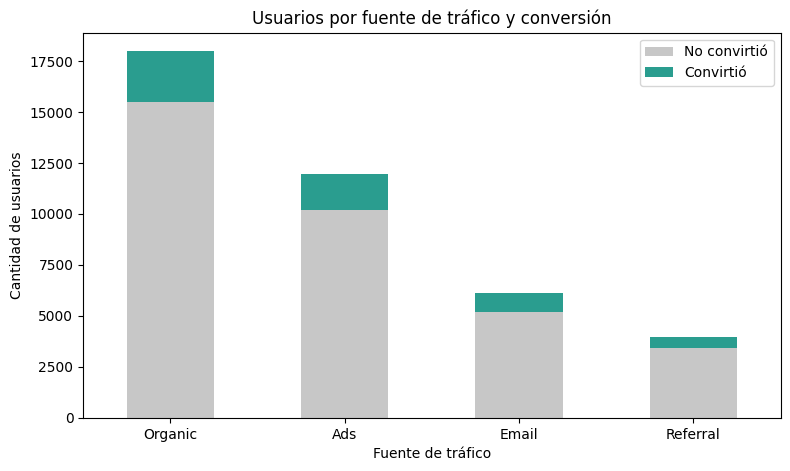

In [34]:
abs_trafico.plot(kind='bar', stacked=True, figsize=(9, 5), color=['#c7c7c7', '#2a9d8f'])
plt.title('Usuarios por fuente de tráfico y conversión')
plt.xlabel('Fuente de tráfico')
plt.ylabel('Cantidad de usuarios')
plt.xticks(rotation=0)
plt.legend(title='')
plt.show()

✍️ **Comentario**: Organic es el canal que más usuarios trae (casi 18.000) y también el que más compras genera (2.480). Le siguen Ads, Email y Referral. Si se mira solo la cantidad, Organic parece el mejor canal, pero eso pasa porque es el que tiene más tráfico, no necesariamente porque convierta mejor.


In [35]:
# Proporción de conversión por canal
prop_trafico = pd.crosstab(df['traffic_source'], df['converted'], normalize='index') * 100
prop_trafico.columns = ['No convirtió', 'Convirtió']
prop_trafico = prop_trafico.sort_values('Convirtió', ascending=False)
prop_trafico.round(2)

,No convirtió,Convirtió
traffic_source,,
Email,85.01,14.99
Ads,85.26,14.74
Referral,86.12,13.88
Organic,86.21,13.79


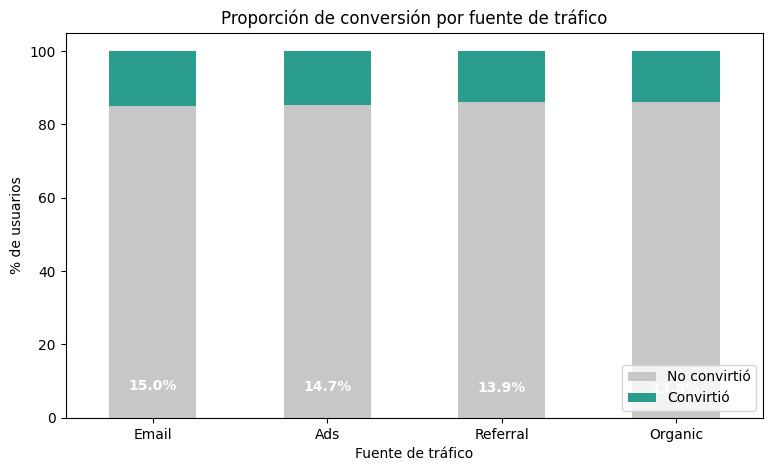

In [36]:
ax = prop_trafico.plot(kind='bar', stacked=True, figsize=(9, 5), color=['#c7c7c7', '#2a9d8f'])
plt.title('Proporción de conversión por fuente de tráfico')
plt.xlabel('Fuente de tráfico')
plt.ylabel('% de usuarios')
plt.xticks(rotation=0)
plt.legend(title='', loc='lower right')

# Etiqueta con el % de conversión
for i, valor in enumerate(prop_trafico['Convirtió']):
    ax.text(i, valor / 2, f'{valor:.1f}%', ha='center', color='white', fontweight='bold')
plt.show()

✍️ **Comentario**: 
Mirando las proporciones, los cuatro canales convierten casi igual, entre un 13,8 % y un 15 %. Email es el que mejor convierte, aunque trae poco tráfico, y Organic es el que menos. La diferencia es de poco más de un punto, lo que calza con la prueba chi-cuadrado: hay relación, pero es muy débil.

### Relación entre el tipo de usuario y la conversión

In [37]:
abs_usuario = pd.crosstab(df['user_type'], df['converted'])
abs_usuario.columns = ['No convirtió', 'Convirtió']
abs_usuario

,No convirtió,Convirtió
user_type,,
Nuevo,22295,3738
Recurrente,11999,1968


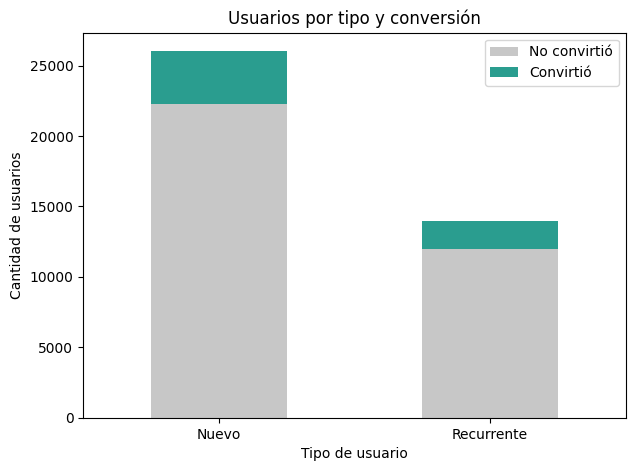

In [38]:
abs_usuario.plot(kind='bar', stacked=True, figsize=(7, 5), color=['#c7c7c7', '#2a9d8f'])
plt.title('Usuarios por tipo y conversión')
plt.xlabel('Tipo de usuario')
plt.ylabel('Cantidad de usuarios')
plt.xticks(rotation=0)
plt.legend(title='')
plt.show()

✍️ **Comentario**: Hay casi el doble de usuarios nuevos (26.033) que recurrentes (13.967), y por lo mismo los nuevos generan más compras (3.738 contra 1.968). Esta diferencia viene del volumen de cada grupo, no de que uno compre más que el otro.

In [39]:
prop_usuario = pd.crosstab(df['user_type'], df['converted'], normalize='index') * 100
prop_usuario.columns = ['No convirtió', 'Convirtió']
prop_usuario.round(2)

,No convirtió,Convirtió
user_type,,
Nuevo,85.64,14.36
Recurrente,85.91,14.09


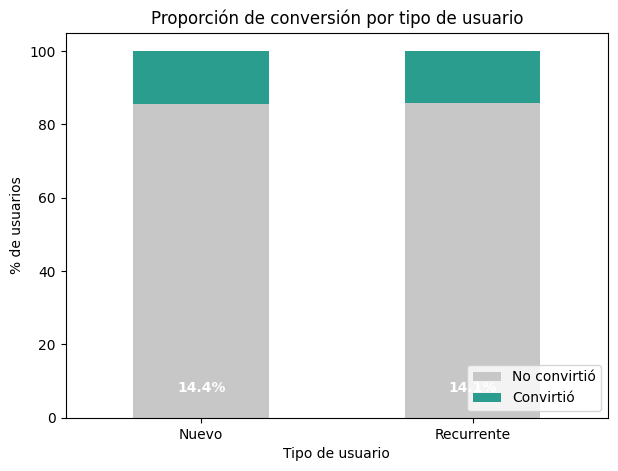

In [40]:
ax = prop_usuario.plot(kind='bar', stacked=True, figsize=(7, 5), color=['#c7c7c7', '#2a9d8f'])
plt.title('Proporción de conversión por tipo de usuario')
plt.xlabel('Tipo de usuario')
plt.ylabel('% de usuarios')
plt.xticks(rotation=0)
plt.legend(title='', loc='lower right')

for i, valor in enumerate(prop_usuario['Convirtió']):
    ax.text(i, valor / 2, f'{valor:.1f}%', ha='center', color='white', fontweight='bold')
plt.show()

✍️ **Comentario**: 
En proporción, las dos barras se ven prácticamente iguales: los nuevos convierten un 14,4 % y los recurrentes un 14,1 %. Esto confirma lo que dio la prueba (p = 0,47): ser nuevo o recurrente no cambia la probabilidad de comprar.

## 🧩 Paso 7. Insight Ejecutivo para Stakeholders

Se traducen los hallazgos del análisis del experimento A/B en conclusiones accionables para el negocio, enfocadas en **versión de página, conversión, gasto promedio, canales de tráfico y tipo de usuario**.

**Preguntas a responder:**  
- ¿Qué página genera mayor conversión y gasto promedio?  
- ¿Qué canales de tráfico son más efectivos para generar conversiones?  
- ¿Existen diferencias significativas según el tipo de usuario?  
- ¿Qué recomendaciones se pueden tomar para optimizar la estrategia de marketing?


---


### ⭐ Insight Ejecutivo basado en el Experimento A/B

#### 🔍 Comparación de página (A vs B)

**Gasto promedio por usuario que convirtió:**
- Los usuarios que compraron en la página B gastaron más en promedio que los de la página A.
- La diferencia es significativa (Welch: t = −9,48, p < 0,0001) y Mann-Whitney dio lo mismo, así que el resultado no depende de que el gasto esté sesgado.
- **Interpretación:** la página B no solo hace que más gente compre, sino que además las compras son más grandes.

**Tasa de conversión:**
- La página A convierte un 12,57 % y la B un 15,96 %, una diferencia de 3,4 puntos (alrededor de un 27 % más de compras).
- La prueba Z da p < 0,0001 y los intervalos de confianza no se cruzan.
- **Interpretación:** por cada 1.000 visitantes, la página B genera unas 34 compras más que la A.

---

#### 📊 Segmentación por fuente de tráfico
- Todos los canales convierten parecido, entre un 13,8 % (Organic) y un 15 % (Email). La prueba chi-cuadrado sale significativa (p = 0,034), pero el efecto es muy débil (V de Cramér = 0,015). Organic es el que más compras trae por volumen (2.480), y en los cuatro canales la página B convierte mejor que la A.
- **Interpretación:** el canal influye poco en la conversión. Organic es importante por la cantidad de tráfico que trae, y Email es el más eficiente.

---

#### 📊 Segmentación por tipo de usuario
- Nuevos (14,4 %) y recurrentes (14,1 %) convierten casi igual, y la diferencia no es significativa (p = 0,47). La página B mejora la conversión en los dos grupos por igual.
- **Interpretación:** no hace falta hacer páginas distintas para nuevos y recurrentes; la misma página B funciona para ambos.

---

Las visualizaciones usadas respaldan los resultados estadísticos de pasos anteriores.

---

#### 💡 Recomendaciones de negocio:
- Implementar la página B para todo el tráfico, porque gana en conversión y en gasto, y lo hace en todos los segmentos.
- Mantener Organic como canal principal por volumen y probar aumentar la inversión en Email, que es el que mejor convierte.
- Seguir midiendo la conversión después del cambio para confirmar que la mejora se mantiene en el tiempo y no es solo un efecto de novedad.